# 04 - Improve and compare models

Run notebooks 01 through 03 first. Compare model and threshold choices using development data only. Use the saved patient folds for outer evaluation and grouped inner folds for tuning.

Keep the original test results unchanged. Report whether F1 improves, including cases where tuning makes it worse.

Section 7 also compares accuracy-based selection with a nested ROC-AUC search. The original test results remain unchanged.

Section 8 tries stronger models and ensembles, freezes one development-selected candidate, and reports one clearly labeled comparison with the original test cohort.

## 1. Load combined inputs

Compare radiomics + metadata with the same inputs plus three extra features: log volume, intensity difference and mask fill ratio. Reuse notebook 03 measurements and the original development folds. Check hashes of the baseline and test files.

In [1]:
from pathlib import Path
import os
import json
import hashlib
import importlib.metadata as metadata
from datetime import datetime, timezone
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from joblib import Parallel, delayed
from threadpoolctl import threadpool_limits
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import VarianceThreshold, SelectPercentile, f_classif
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_score, recall_score, confusion_matrix

ROOT = Path.cwd().resolve()
if not (ROOT / 'MetadatabyNoduleMaxVoting.xlsx').exists() and (ROOT.parent / 'MetadatabyNoduleMaxVoting.xlsx').exists():
    ROOT = ROOT.parent
OUTPUT_SUBDIR = os.environ.get('LUNA_OUTPUT_SUBDIR', '')
assert OUTPUT_SUBDIR in ('', 'smoke')
SMOKE = os.environ.get('LUNA_SMOKE', '0') == '1'
BASE = ROOT / 'artifacts' / OUTPUT_SUBDIR
MODEL_OUT, FE_OUT, RAD_OUT = BASE / 'modeling', BASE / 'feature_engineering', BASE / 'radiomics'
OUT = BASE / 'f1_optimization'
OUT.mkdir(parents=True, exist_ok=True)
KEYS = ['patient_id', 'nodule_id', 'seriesuid']
SEED = 42

def save_json(data, path):
    path.write_text(json.dumps(data, indent=2), encoding='utf-8')

def sha256_file(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

assert (FE_OUT / 'experiment.json').is_file(), 'Run notebook 03 first.'
previous = json.loads((FE_OUT / 'experiment.json').read_text(encoding='utf-8'))
assert not previous['smoke_run'] or (SMOKE and OUTPUT_SUBDIR == 'smoke')
schema = json.loads((MODEL_OUT / 'model_schema.json').read_text(encoding='utf-8'))
extraction = json.loads((RAD_OUT / 'extraction_run.json').read_text(encoding='utf-8'))
VERSIONS = {name: metadata.version(name) for name in ['numpy', 'pandas', 'scikit-learn', 'joblib', 'SimpleITK', 'pyradiomics', 'PyWavelets']}
for name in VERSIONS:
    assert VERSIONS[name] == schema['versions'][name], 'Environment differs from baseline: ' + name
assert previous['engineered_features_sha256'] == sha256_file(FE_OUT / 'engineered_features_development.csv')
assert schema['split_sha256'] == sha256_file(MODEL_OUT / 'split_assignments.csv')
assert schema['extraction_features_sha256'] == sha256_file(RAD_OUT / 'radiomics_features.csv')
protected = {str((MODEL_OUT / name).relative_to(BASE)): sha256_file(MODEL_OUT / name)
             for name in previous['protected_artifacts_sha256']}
protected.update({str((FE_OUT / name).relative_to(BASE)): sha256_file(FE_OUT / name)
                  for name in ['experiment.json', 'engineered_features_development.csv', 'baseline_oof_combined.csv']})
for name, digest in previous['protected_artifacts_sha256'].items():
    assert sha256_file(MODEL_OUT / name) == digest

splits = pd.read_csv(MODEL_OUT / 'split_assignments.csv', dtype={'patient_id': str, 'seriesuid': str})
development_keys = splits.loc[splits['partition'].eq('development'), KEYS + ['target', 'development_cv_fold']]
all_data = pd.read_csv(MODEL_OUT / 'modeling_dataset.csv', dtype={'patient_id': str, 'seriesuid': str})
dev = all_data.drop(columns='target').merge(development_keys, on=KEYS, how='inner', validate='one_to_one').sort_values(KEYS).reset_index(drop=True)
del all_data
engineered = pd.read_csv(FE_OUT / 'engineered_features_development.csv', dtype={'patient_id': str, 'seriesuid': str})
dev = dev.merge(engineered, on=KEYS, how='left', validate='one_to_one')
assert len(dev) == previous['development_nodules']
assert not set(dev['patient_id']) & set(splits.loc[splits['partition'].eq('test'), 'patient_id'])

TAB_NUMERIC = ['diameter_mm', 'Lobulation_value', 'Margin_value', 'Sphericity_value',
               'Spiculation_value', 'Subtlety_value', 'Texture_value']
TAB_CATEGORICAL = ['Calcification_value', 'InternalStructure_value']
RAD_COLUMNS = sorted(c for c in dev if c.startswith('rad_original_'))
CURATED = ['log_volume', 'intensity_difference', 'mask_fill_ratio']
FEATURE_VARIANTS = {
    'combined': TAB_NUMERIC + RAD_COLUMNS,
    'combined_curated': TAB_NUMERIC + RAD_COLUMNS + CURATED,
}
ALL_COLUMNS = TAB_NUMERIC + TAB_CATEGORICAL + RAD_COLUMNS + CURATED
assert not set(ALL_COLUMNS) & set(KEYS + ['Diagnosis', 'Diagnosis_value', 'Malignancy', 'Malignancy_value', 'target', 'len_mal_details'])
X_dev = dev[ALL_COLUMNS].apply(pd.to_numeric, errors='raise').replace([np.inf, -np.inf], np.nan)
y_dev, groups_dev = dev['target'].astype(int), dev['patient_id']
outer_folds = sorted(dev['development_cv_fold'].unique())
assert outer_folds == list(range(3 if SMOKE else 5))
outer_splits = [(np.flatnonzero(dev['development_cv_fold'].to_numpy() != fold),
                 np.flatnonzero(dev['development_cv_fold'].to_numpy() == fold)) for fold in outer_folds]
baseline_bundle = joblib.load(MODEL_OUT / 'combined_best_model.joblib')
baseline_oof = pd.read_csv(FE_OUT / 'baseline_oof_combined.csv', dtype={'patient_id': str, 'seriesuid': str})
baseline_oof = dev[KEYS].merge(baseline_oof, on=KEYS, how='left', validate='one_to_one')
assert baseline_oof['score_malign'].notna().all()
print('Development:', len(dev), 'nodules /', groups_dev.nunique(), 'patients')

Development: 786 nodules / 435 patients


## 2. Set candidates and thresholds

Try logistic regression, random forest and histogram gradient boosting on both input groups: 28 candidates in a full run. Use balanced class weights. Disable boosting early stopping to avoid a random internal split across patients.

For each candidate, collect inner-validation scores and choose the threshold with the best mean fold F1. Try 0.10 to 0.90 in steps of 0.025. Break ties by closeness to 0.5, then the lower threshold. Never use outer-validation labels for these choices.

In [2]:
THRESHOLDS = np.round(np.arange(0.10, 0.9001, 0.025), 3)

def grouped_splits(X, y, groups, n_splits, seed):
    cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    result = list(cv.split(X, y, groups))
    coverage = np.zeros(len(X), dtype=int)
    groups, y = np.asarray(groups), np.asarray(y)
    for train, validation in result:
        assert not set(groups[train]) & set(groups[validation])
        assert np.unique(y[train]).size == 2 and np.unique(y[validation]).size == 2
        coverage[validation] += 1
    assert (coverage == 1).all()
    return result

def choose_threshold(y, probability, fold_ids, thresholds):
    y, probability, fold_ids = np.asarray(y), np.asarray(probability), np.asarray(fold_ids)
    thresholds = np.asarray(thresholds)
    assert len(y) == len(probability) == len(fold_ids)
    assert np.isfinite(probability).all() and (fold_ids >= 0).all()
    assert set(np.unique(y)) == {0, 1}
    assert ((thresholds > 0) & (thresholds < 1)).all()
    decisions = probability[:, None] >= thresholds[None, :]
    fold_scores = []
    for fold in sorted(np.unique(fold_ids)):
        selected = fold_ids == fold
        actual = y[selected, None] == 1
        predicted = decisions[selected]
        tp = (predicted & actual).sum(axis=0)
        fp = (predicted & ~actual).sum(axis=0)
        fn = (~predicted & actual).sum(axis=0)
        denominator = 2 * tp + fp + fn
        scores = np.divide(2 * tp, denominator, out=np.zeros(len(thresholds)), where=denominator != 0)
        fold_scores.append(scores)
    curve = np.mean(fold_scores, axis=0)
    tied = np.flatnonzero(np.isclose(curve, curve.max(), rtol=0, atol=1e-12))
    best = min(tied, key=lambda idx: (abs(float(thresholds[idx]) - 0.5), float(thresholds[idx])))
    return float(thresholds[best]), float(curve[best]), curve

def make_pipeline(numeric, classifier, percentile):
    numeric_steps = Pipeline([
        ('impute', SimpleImputer(strategy='median', keep_empty_features=True)),
        ('scale', StandardScaler()),
    ])
    categorical_steps = Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent', keep_empty_features=True)),
        ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ])
    return Pipeline([
        ('preprocess', ColumnTransformer([('numeric', numeric_steps, numeric),
                                         ('categorical', categorical_steps, TAB_CATEGORICAL)],
                                        remainder='drop', verbose_feature_names_out=True)),
        ('variance', VarianceThreshold()),
        ('select', SelectPercentile(f_classif, percentile=percentile)),
        ('classifier', classifier),
    ])

def candidate_specs():
    specs = []
    for variant in FEATURE_VARIANTS:
        for c in ([0.1] if SMOKE else [0.1, 1.0, 10.0]):
            for percentile in ([50] if SMOKE else [50, 100]):
                specs.append({'feature_variant': variant, 'model': 'logistic', 'percentile': percentile, 'params': {'C': c}})
        for depth in ([6] if SMOKE else [6, None]):
            for leaf in ([2] if SMOKE else [2, 5]):
                specs.append({'feature_variant': variant, 'model': 'random_forest', 'percentile': 100,
                              'params': {'max_depth': depth, 'min_samples_leaf': leaf}})
        for nodes in ([7] if SMOKE else [7, 15]):
            for leaf in ([10] if SMOKE else [10, 20]):
                specs.append({'feature_variant': variant, 'model': 'hist_gradient_boosting', 'percentile': 100,
                              'params': {'max_leaf_nodes': nodes, 'min_samples_leaf': leaf}})
    for number, spec in enumerate(specs):
        spec['candidate_id'] = number
    return specs

def pipeline_for_spec(spec):
    common = {'class_weight': 'balanced', 'random_state': SEED}
    if spec['model'] == 'logistic':
        classifier = LogisticRegression(max_iter=5000, solver='liblinear', **common, **spec['params'])
    elif spec['model'] == 'random_forest':
        classifier = RandomForestClassifier(n_estimators=100 if SMOKE else 200, n_jobs=1, **common, **spec['params'])
    elif spec['model'] == 'hist_gradient_boosting':
        classifier = HistGradientBoostingClassifier(max_iter=60 if SMOKE else 200, learning_rate=0.05,
            l2_regularization=1.0, early_stopping=False, **common, **spec['params'])
    else:
        raise ValueError('Unknown model family')
    return make_pipeline(FEATURE_VARIANTS[spec['feature_variant']], classifier, spec['percentile'])

def inner_candidate(pipeline, X, y, inner_splits):
    probability = np.full(len(X), np.nan)
    fold_ids = np.full(len(X), -1)
    aucs = []
    with threadpool_limits(limits=1):
        for fold, (train, validation) in enumerate(inner_splits):
            estimator = clone(pipeline).fit(X.iloc[train], y.iloc[train])
            scores = estimator.predict_proba(X.iloc[validation])[:, 1]
            probability[validation], fold_ids[validation] = scores, fold
            aucs.append(roc_auc_score(y.iloc[validation], scores))
    threshold, f1, curve = choose_threshold(y, probability, fold_ids, THRESHOLDS)
    default_idx = int(np.flatnonzero(np.isclose(THRESHOLDS, 0.5))[0])
    assert f1 + 1e-12 >= curve[default_idx]
    return {'threshold': threshold, 'inner_mean_f1': f1, 'inner_mean_roc_auc': float(np.mean(aucs)),
            'inner_mean_f1_at_05': float(curve[default_idx]), 'threshold_curve': curve.tolist()}

def search_inner(X, y, inner_splits, specs):
    evaluated = Parallel(n_jobs=2)(delayed(inner_candidate)(pipeline_for_spec(spec), X, y, inner_splits) for spec in specs)
    results = [{**spec, **score} for spec, score in zip(specs, evaluated)]
    ranked = sorted(results, key=lambda row: (-row['inner_mean_f1'], -row['inner_mean_roc_auc'],
                                             abs(row['threshold'] - 0.5), row['candidate_id']))
    return ranked[0], results

SPECS = candidate_specs()
save_json({'candidates': SPECS, 'thresholds': THRESHOLDS.tolist()}, OUT / 'candidate_grid.json')
print('Candidates:', len(SPECS), '| thresholds:', len(THRESHOLDS))

Candidates: 28 | thresholds: 33


## 3. Evaluate on outer folds

Tune using three inner folds for each outer training set (two in smoke mode). Freeze the model and threshold before predicting its outer-validation fold. Save fold scores, predictions and patient assignments.

Compare the old combined model at 0.5, threshold tuning alone, and model selection with or without threshold tuning. The old model settings were chosen on development data earlier, so this fixed reference is descriptive.

In [3]:
def metric_row(labels, probability, threshold):
    predicted = (np.asarray(probability) >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels, predicted, labels=[0, 1]).ravel()
    return {
        'f1_malign': float(f1_score(labels, predicted, zero_division=0)),
        'precision_malign': float(precision_score(labels, predicted, zero_division=0)),
        'recall_malign': float(recall_score(labels, predicted, zero_division=0)),
        'specificity_benign': float(tn / (tn + fp)),
        'roc_auc': float(roc_auc_score(labels, probability)),
        'average_precision': float(average_precision_score(labels, probability)),
    }

def inner_audit_rows(outer_fold, training_positions, inner_splits, validation_positions):
    rows = []
    forbidden_patients = set(groups_dev.iloc[validation_positions])
    for fold, (train, validation) in enumerate(inner_splits):
        for role, local_indices in [('train', train), ('validation', validation)]:
            absolute_indices = training_positions[local_indices]
            assert not forbidden_patients & set(groups_dev.iloc[absolute_indices])
            for identifiers in dev.iloc[absolute_indices][KEYS].to_dict(orient='records'):
                rows.append({'outer_fold': outer_fold, 'inner_fold': fold, 'role': role, **identifiers})
    return rows

outer_rows, audit_rows, selected_recipes = [], [], []
oof_rows = []
started = time.perf_counter()
for fold, (train, validation) in enumerate(outer_splits):
    assert not set(groups_dev.iloc[train]) & set(groups_dev.iloc[validation])
    X_train, y_train, g_train = X_dev.iloc[train], y_dev.iloc[train], groups_dev.iloc[train]
    inner = grouped_splits(X_train, y_train, g_train, 2 if SMOKE else 3, SEED + 100 + fold)
    audit_rows.extend(inner_audit_rows(fold, train, inner, validation))
    selected, inner_results = search_inner(X_train, y_train, inner, SPECS)
    save_json(inner_results, OUT / f'outer_{fold}_inner_search.json')
    baseline_threshold_result = inner_candidate(baseline_bundle['pipeline'], X_train, y_train, inner)
    baseline_threshold = baseline_threshold_result['threshold']

    with threadpool_limits(limits=1):
        fixed_baseline = clone(baseline_bundle['pipeline']).fit(X_train, y_train)
        baseline_probability = fixed_baseline.predict_proba(X_dev.iloc[validation])[:, 1]
        selected_pipeline = pipeline_for_spec(selected).fit(X_train, y_train)
        selected_probability = selected_pipeline.predict_proba(X_dev.iloc[validation])[:, 1]
    np.testing.assert_allclose(baseline_probability, baseline_oof.iloc[validation]['score_malign'], rtol=1e-10, atol=1e-10)
    labels = y_dev.iloc[validation]
    methods = {
        'baseline_combined_05': (baseline_probability, 0.5),
        'baseline_threshold_tuned': (baseline_probability, baseline_threshold),
        'f1_selected_model_05': (selected_probability, 0.5),
        'f1_selected_model_threshold': (selected_probability, selected['threshold']),
    }
    for method, (probability, threshold) in methods.items():
        outer_rows.append({'outer_fold': fold, 'method': method, 'threshold': threshold,
                           **metric_row(labels, probability, threshold)})
        records = dev.iloc[validation][KEYS + ['target']].copy()
        records['outer_fold'], records['method'] = fold, method
        records['score_malign'], records['threshold'] = probability, threshold
        records['prediction'] = (probability >= threshold).astype(int)
        oof_rows.extend(records.to_dict(orient='records'))
    selected_recipes.append({'outer_fold': fold, **selected, 'baseline_threshold': baseline_threshold})
    pd.DataFrame(outer_rows).to_csv(OUT / 'outer_fold_results.csv', index=False)
    pd.DataFrame(audit_rows).to_csv(OUT / 'inner_group_assignments.csv', index=False)
    save_json(selected_recipes, OUT / 'outer_selected_recipes.json')
    joblib.dump({'pipeline': selected_pipeline, 'threshold': selected['threshold'],
                 'recipe': selected, 'outer_fold': fold}, OUT / f'outer_{fold}_model.joblib')
    tuned_score = outer_rows[-1]['f1_malign']
    print(f'Outer fold {fold + 1}/{len(outer_splits)}: {selected["model"]}, {selected["feature_variant"]}, '
          f'threshold {selected["threshold"]:.3f}, held-fold F1 {tuned_score:.4f}; elapsed {time.perf_counter() - started:.1f}s')

outer_results = pd.DataFrame(outer_rows)
oof = pd.DataFrame(oof_rows)
assert oof.groupby('method').size().eq(len(dev)).all()
assert not oof.duplicated(KEYS + ['method']).any()
oof.to_csv(OUT / 'development_outer_oof_predictions.csv', index=False)
summary = outer_results.groupby('method').agg(
    mean_f1=('f1_malign', 'mean'), std_f1=('f1_malign', lambda values: values.std(ddof=0)),
    mean_precision=('precision_malign', 'mean'), mean_recall=('recall_malign', 'mean'),
    mean_specificity=('specificity_benign', 'mean'), mean_roc_auc=('roc_auc', 'mean'),
    mean_average_precision=('average_precision', 'mean'),
).reset_index()
baseline_folds = pd.read_csv(FE_OUT / 'baseline_folds_combined.csv')
np.testing.assert_allclose(summary.loc[summary['method'].eq('baseline_combined_05'), 'mean_f1'].iloc[0],
                           baseline_folds['f1_malign'].mean(), rtol=1e-10)
summary.to_csv(OUT / 'outer_cv_summary.csv', index=False)
display(summary.round(4))

D:\Github\LUNA-lung-cancer-analysis\.venv-radiomics\lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "D:\Github\LUNA-lung-cancer-analysis\.venv-radiomics\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "C:\Users\ACER\AppData\Roaming\uv\python\cpython-3.9.25-windows-x86_64-none\lib\subprocess.py", line 505, in run
    with Popen(*popenargs, **kwargs) as process:
  File "C:\Users\ACER\AppData\Roaming\uv\python\cpython-3.9.25-windows-x86_64-none\lib\subprocess.py", line 951, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\ACER\AppData\Roaming

Outer fold 1/5: hist_gradient_boosting, combined_curated, threshold 0.250, held-fold F1 0.7619; elapsed 41.4s


Outer fold 2/5: logistic, combined, threshold 0.600, held-fold F1 0.8438; elapsed 85.5s


Outer fold 3/5: logistic, combined, threshold 0.575, held-fold F1 0.8000; elapsed 128.3s


Outer fold 4/5: logistic, combined, threshold 0.550, held-fold F1 0.8283; elapsed 171.0s


Outer fold 5/5: logistic, combined_curated, threshold 0.525, held-fold F1 0.7797; elapsed 183.5s


,method,mean_f1,std_f1,mean_precision,mean_recall,mean_specificity,mean_roc_auc,mean_average_precision
0,baseline_combined_05,0.8312,0.0291,0.7958,0.8720,0.8738,0.9344,0.9055
1,baseline_threshold_tuned,0.8155,0.0239,0.7895,0.8473,0.8724,0.9344,0.9055
2,f1_selected_model_05,0.8106,0.0371,0.7937,0.8358,0.8758,0.9238,0.9002
3,f1_selected_model_threshold,0.8027,0.0301,0.7903,0.8220,0.8718,0.9238,0.9002


## 4. Fit a candidate on development data

Repeat the same search on all development patients, using the saved folds for selection. Fit and save the chosen model with its threshold. The best inner score is a selection estimate. Outer CV evaluates the selection process, not an independent test score for this final saved model.

In [4]:
final_recipe, final_search = search_inner(X_dev, y_dev, outer_splits, SPECS)
save_json(final_search, OUT / 'final_development_search.json')
with threadpool_limits(limits=1):
    final_pipeline = pipeline_for_spec(final_recipe).fit(X_dev, y_dev)
encoded = np.asarray(final_pipeline.named_steps['preprocess'].get_feature_names_out())
nonconstant = encoded[final_pipeline.named_steps['variance'].get_support()]
selected_names = nonconstant[final_pipeline.named_steps['select'].get_support()]
assert any('rad_original_' in name for name in selected_names), 'Combined candidate must retain radiomics.'
numeric = FEATURE_VARIANTS[final_recipe['feature_variant']]
bundle = {
    'pipeline': final_pipeline, 'threshold': final_recipe['threshold'],
    'required_inputs': numeric + TAB_CATEGORICAL,
    'feature_set': final_recipe['feature_variant'], 'model': final_recipe['model'],
    'selected_features': selected_names.tolist(), 'recipe': final_recipe,
    'engineered_features': CURATED if final_recipe['feature_variant'] == 'combined_curated' else [],
    'engineering_protocol': 'native-lps-eda-eight-v1',
    'radiomics_protocol_id': extraction['protocol_id'],
    'radiomics_params_yaml': (RAD_OUT / 'radiomics_params.yaml').read_text(encoding='utf-8'),
    'preprocess_revision': extraction['preprocess_revision'], 'versions': VERSIONS,
    'label_mapping': {0: 'BENIGN', 1: 'MALIGN'}, 'fitted_partition': 'development',
    'selection_metric': 'f1_malign', 'test_evaluated': False,
}
model_path = OUT / 'f1_optimized_combined_model.joblib'
joblib.dump(bundle, model_path)
reloaded = joblib.load(model_path)
with threadpool_limits(limits=1):
    np.testing.assert_allclose(reloaded['pipeline'].predict_proba(X_dev), final_pipeline.predict_proba(X_dev))
schema_out = {name: value for name, value in bundle.items() if name not in ['pipeline', 'radiomics_params_yaml']}
save_json(schema_out, OUT / 'model_schema.json')
print('Development-fitted candidate:', final_recipe['model'], final_recipe['feature_variant'],
      'threshold', final_recipe['threshold'], 'params', final_recipe['params'])
print('Final-search inner F1 (selection estimate):', round(final_recipe['inner_mean_f1'], 4))

Development-fitted candidate: logistic combined_curated threshold 0.5 params {'C': 0.1}
Final-search inner F1 (selection estimate): 0.8328


## 5. Check predictions and report results

Apply the saved threshold to scores when making labels. Check model reloads and show one development prediction; this is not a test result.

For a new VOI, use notebook 01 extraction settings and supply metadata. If required, add the three native-image measurements from notebook 03. Check that protected baseline and test files have not changed.

,score_malign,prediction,predicted_label
0,0.998896,1,MALIGN


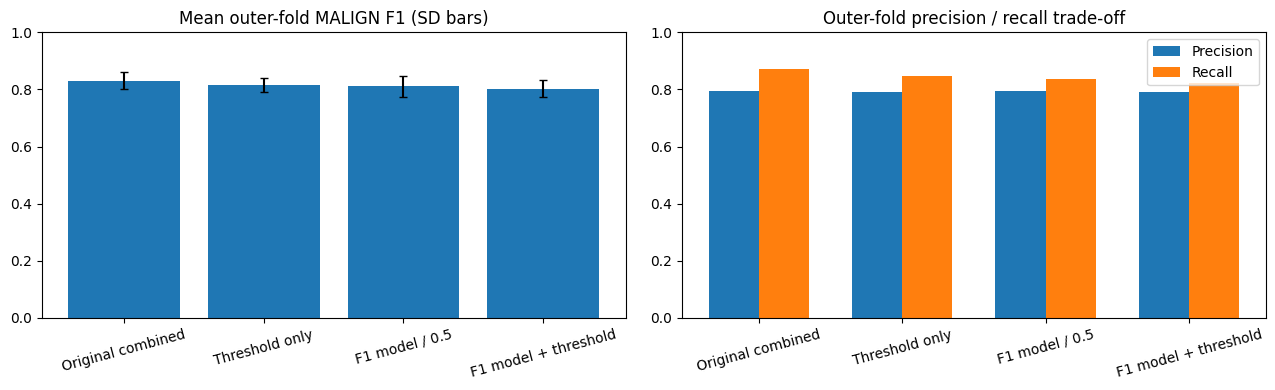

Mean outer F1: 0.8312 -> 0.8027
Threshold-only mean outer F1: 0.8155
Baseline and test files unchanged; no new test evaluation.


In [5]:
def predict_feature_rows(model_bundle, rows):
    frame = pd.DataFrame(rows).copy()
    missing = set(model_bundle['required_inputs']) - set(frame.columns)
    if missing:
        raise ValueError('Missing required input columns: ' + ', '.join(sorted(missing)))
    frame = frame[model_bundle['required_inputs']].apply(pd.to_numeric, errors='raise').replace([np.inf, -np.inf], np.nan)
    with threadpool_limits(limits=1):
        probability = model_bundle['pipeline'].predict_proba(frame)[:, 1]
    prediction = (probability >= model_bundle['threshold']).astype(int)
    return pd.DataFrame({'score_malign': probability, 'prediction': prediction,
                         'predicted_label': [model_bundle['label_mapping'][int(value)] for value in prediction]})

display(predict_feature_rows(reloaded, X_dev.iloc[[0]]))
order = ['baseline_combined_05', 'baseline_threshold_tuned', 'f1_selected_model_05', 'f1_selected_model_threshold']
plot_data = summary.set_index('method').loc[order]
labels = ['Original combined', 'Threshold only', 'F1 model / 0.5', 'F1 model + threshold']
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(labels, plot_data['mean_f1'], yerr=plot_data['std_f1'], capsize=3)
axes[0].set_ylim(0, 1)
axes[0].set_title('Mean outer-fold MALIGN F1 (SD bars)')
axes[0].tick_params(axis='x', rotation=15)
positions, width = np.arange(len(labels)), 0.35
axes[1].bar(positions - width / 2, plot_data['mean_precision'], width, label='Precision')
axes[1].bar(positions + width / 2, plot_data['mean_recall'], width, label='Recall')
axes[1].set_xticks(positions, labels, rotation=15)
axes[1].set_ylim(0, 1)
axes[1].set_title('Outer-fold precision / recall trade-off')
axes[1].legend()
plt.tight_layout()
plt.savefig(OUT / 'f1_optimization_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

assert protected == {name: sha256_file(BASE / name) for name in protected}, 'A protected baseline/test artifact changed.'
baseline_mean = float(plot_data.loc['baseline_combined_05', 'mean_f1'])
optimized_mean = float(plot_data.loc['f1_selected_model_threshold', 'mean_f1'])
threshold_only_mean = float(plot_data.loc['baseline_threshold_tuned', 'mean_f1'])
experiment = {
    'created_at_utc': datetime.now(timezone.utc).isoformat(), 'versions': VERSIONS,
    'development_nodules': len(dev), 'development_patients': groups_dev.nunique(),
    'outer_folds': len(outer_splits), 'inner_folds': 2 if SMOKE else 3,
    'n_candidates': len(SPECS), 'thresholds': THRESHOLDS.tolist(), 'selection_metric': 'f1_malign',
    'test_evaluated': False, 'smoke_run': SMOKE, 'final_recipe': final_recipe,
    'outer_cv_summary': summary.to_dict(orient='records'),
    'delta_mean_f1_optimized_vs_baseline': optimized_mean - baseline_mean,
    'delta_mean_f1_threshold_only_vs_baseline': threshold_only_mean - baseline_mean,
    'protected_artifacts_sha256': protected,
}
save_json(experiment, OUT / 'experiment.json')
report_lines = [
    '# F1 tuning results', '',
    f'{len(dev)} development nodules from {groups_dev.nunique()} patients. '
    f'Use {len(outer_splits)} outer folds and {2 if SMOKE else 3} grouped inner folds.', '',
    'Select models and thresholds by MALIGN F1. Both input groups include radiomics and metadata; one adds three native-image features. Try logistic regression, random forest and histogram gradient boosting.', '',
    '| Method | Outer CV F1 | F1 SD | Precision | Recall | ROC-AUC |',
    '|---|---:|---:|---:|---:|---:|',
]
method_labels = dict(zip(order, ['Original combined, 0.5', 'Original combined, tuned threshold',
                                'F1-selected model, 0.5', 'F1-selected model and threshold']))
for method in order:
    row = plot_data.loc[method]
    report_lines.append(f'| {method_labels[method]} | {row["mean_f1"]:.4f} | {row["std_f1"]:.4f} | '
                        f'{row["mean_precision"]:.4f} | {row["mean_recall"]:.4f} | {row["mean_roc_auc"]:.4f} |')
report_lines += ['', f'Mean F1 with model/threshold selection is {optimized_mean:.4f}; '
                 f'change from the fixed original model: {(optimized_mean - baseline_mean) * 100:+.2f} percentage points.', '',
                 'Choices by outer fold:', '', '| Fold | Model | Inputs | Threshold |', '|---|---|---|---:|']
for row in selected_recipes:
    report_lines.append(f'| {row["outer_fold"] + 1} | {row["model"]} | {row["feature_variant"]} | {row["threshold"]:.3f} |')
report_lines += ['',
    f'Development-fitted candidate: **{final_recipe["model"]} / {final_recipe["feature_variant"]}**, '
    f'threshold **{final_recipe["threshold"]:.3f}**, percentile {final_recipe["percentile"]}, parameters `{json.dumps(final_recipe["params"], sort_keys=True)}`.', '',
    'Saved to `artifacts/f1_optimization/f1_optimized_combined_model.joblib`. Apply its threshold to scores. The best inner score is a selection estimate.', '',
    'Outer CV evaluates the selection process; models may differ across folds. The fixed original settings were selected on development earlier. These results are exploratory and do not prove independent improvement.', '',
    'Baseline and test files are unchanged, checked by hash. Do not directly compare these CV scores with the metadata forest test F1 of 85.27%. The new model has no independent test score.', '',
    'See plots in [notebook 04](04_f1_optimization.ipynb). Fold scores, search grids, patient assignments, predictions and models are in `artifacts/f1_optimization/`.', '']
report_text = '\n'.join(report_lines)
(OUT / 'F1_OPTIMIZATION_RESULTS.md').write_text(report_text, encoding='utf-8')
print('Mean outer F1:', round(baseline_mean, 4), '->', round(optimized_mean, 4))
print('Threshold-only mean outer F1:', round(threshold_only_mean, 4))
print('Baseline and test files unchanged; no new test evaluation.')

## 6. Compare two nested searches

Repeat the original combined-input search inside each outer training fold: six logistic and eight forest settings, selected by inner ROC-AUC with threshold 0.5. Reuse inner results where possible.

Both procedures use the same patient folds, but F1 tuning also tries boosting and extra features. Do not change the search after viewing outer results. This is still a development experiment and needs independent validation.

In [6]:
def original_grid_order(row):
    if row['model'] == 'logistic':
        return [0.1, 1.0, 10.0].index(row['params']['C']) * 2 + [50, 100].index(row['percentile'])
    return (6 + [None, 6].index(row['params']['max_depth']) * 4
            + [2, 5].index(row['params']['min_samples_leaf']) * 2
            + [50, 100].index(row['percentile']))

reference_rows, reference_predictions, reference_recipes = [], [], []
for fold, (train, validation) in enumerate(outer_splits):
    X_train, y_train = X_dev.iloc[train], y_dev.iloc[train]
    inner = grouped_splits(X_train, y_train, groups_dev.iloc[train], 2 if SMOKE else 3, SEED + 100 + fold)
    saved_results = json.loads((OUT / f'outer_{fold}_inner_search.json').read_text(encoding='utf-8'))
    matching = [row for row in saved_results if row['feature_variant'] == 'combined'
                and row['model'] in ['logistic', 'random_forest']]
    if SMOKE:
        matching = [row for row in matching if row['model'] == 'logistic']
        missing_specs = [{'feature_variant': 'combined', 'model': 'random_forest', 'percentile': 50,
                          'params': {'max_depth': None, 'min_samples_leaf': 2}, 'candidate_id': 1000}]
    else:
        assert len(matching) == 10
        missing_specs = [{'feature_variant': 'combined', 'model': 'random_forest', 'percentile': 50,
                          'params': {'max_depth': depth, 'min_samples_leaf': leaf}, 'candidate_id': 1000 + number}
                         for number, (depth, leaf) in enumerate((depth, leaf) for depth in [None, 6] for leaf in [2, 5])]
    additional = Parallel(n_jobs=2)(delayed(inner_candidate)(pipeline_for_spec(spec), X_train, y_train, inner)
                                  for spec in missing_specs)
    reference_search = matching + [{**spec, **score} for spec, score in zip(missing_specs, additional)]
    assert len(reference_search) == (2 if SMOKE else 14)
    selected = sorted(reference_search, key=lambda row: (-row['inner_mean_roc_auc'], original_grid_order(row)))[0]
    with threadpool_limits(limits=1):
        estimator = pipeline_for_spec(selected).fit(X_train, y_train)
        probability = estimator.predict_proba(X_dev.iloc[validation])[:, 1]
    reference_rows.append({'outer_fold': fold, 'method': 'roc_auc_selected_model_05', 'threshold': 0.5,
                           **metric_row(y_dev.iloc[validation], probability, 0.5)})
    rows = dev.iloc[validation][KEYS + ['target']].copy()
    rows['outer_fold'], rows['method'] = fold, 'roc_auc_selected_model_05'
    rows['score_malign'], rows['threshold'] = probability, 0.5
    rows['prediction'] = (probability >= 0.5).astype(int)
    reference_predictions.extend(rows.to_dict(orient='records'))
    reference_recipes.append({'outer_fold': fold, **selected})
    save_json(reference_search, OUT / f'outer_{fold}_roc_auc_reference_search.json')
    print('Nested ROC-AUC reference fold', fold + 1, selected['model'], 'F1:', round(reference_rows[-1]['f1_malign'], 4))

reference = pd.DataFrame(reference_rows)
reference.to_csv(OUT / 'nested_roc_auc_reference_folds.csv', index=False)
pd.DataFrame(reference_predictions).to_csv(OUT / 'nested_roc_auc_reference_oof.csv', index=False)
save_json(reference_recipes, OUT / 'nested_roc_auc_reference_recipes.json')
new_results = pd.read_csv(OUT / 'outer_fold_results.csv')
same_level = pd.concat([reference, new_results.loc[new_results['method'].eq('f1_selected_model_threshold')]], ignore_index=True)
same_level_summary = same_level.groupby('method').agg(
    mean_f1=('f1_malign', 'mean'), std_f1=('f1_malign', lambda values: values.std(ddof=0)),
    mean_precision=('precision_malign', 'mean'), mean_recall=('recall_malign', 'mean'),
    mean_roc_auc=('roc_auc', 'mean'),
).reset_index()
same_level_summary.to_csv(OUT / 'nested_procedure_comparison.csv', index=False)
display(same_level_summary.round(4))
roc_f1 = float(same_level_summary.loc[same_level_summary['method'].eq('roc_auc_selected_model_05'), 'mean_f1'].iloc[0])
new_f1 = float(same_level_summary.loc[same_level_summary['method'].eq('f1_selected_model_threshold'), 'mean_f1'].iloc[0])
experiment = json.loads((OUT / 'experiment.json').read_text(encoding='utf-8'))
experiment['nested_roc_auc_reference_comparison'] = same_level_summary.to_dict(orient='records')
experiment['delta_mean_f1_vs_nested_roc_auc_reference'] = new_f1 - roc_f1
save_json(experiment, OUT / 'experiment.json')
assert protected == {name: sha256_file(BASE / name) for name in protected}

addition = [
    '', '## Nested search comparison', '',
    'Repeat the original ROC-AUC search inside each outer training fold: six logistic and eight forest settings, threshold 0.5. Both procedures use the same patient folds. F1 tuning also tries boosting and extra features, so search spaces differ.', '',
    '| Procedure | Outer CV F1 | F1 SD | Precision | Recall | ROC-AUC |',
    '|---|---:|---:|---:|---:|---:|',
]
for row in same_level_summary.to_dict(orient='records'):
    name = 'F1 model/threshold selection' if row['method'] == 'f1_selected_model_threshold' else 'ROC-AUC model selection, 0.5'
    addition.append(f'| {name} | {row["mean_f1"]:.4f} | {row["std_f1"]:.4f} | {row["mean_precision"]:.4f} | {row["mean_recall"]:.4f} | {row["mean_roc_auc"]:.4f} |')
addition += ['',
    f'F1 tuning changes mean F1 by {(new_f1 - roc_f1) * 100:+.2f} percentage points. Outer results were not used to revise candidates or thresholds. These are development CV scores, not independent test scores.', '',
    'Labels come from radiologist ratings, not pathology-confirmed cancer.', '']
path = OUT / 'F1_OPTIMIZATION_RESULTS.md'
report = path.read_text(encoding='utf-8') + '\n'.join(addition)
path.write_text(report, encoding='utf-8')
print('Nested comparison F1:', round(roc_f1, 4), '->', round(new_f1, 4))

Nested ROC-AUC reference fold 1 random_forest F1: 0.7692


Nested ROC-AUC reference fold 2 logistic F1: 0.8657


Nested ROC-AUC reference fold 3 logistic F1: 0.8276


Nested ROC-AUC reference fold 4 logistic F1: 0.8598


Nested ROC-AUC reference fold 5 logistic F1: 0.8167


,method,mean_f1,std_f1,mean_precision,mean_recall,mean_roc_auc
0,f1_selected_model_threshold,0.8027,0.0301,0.7903,0.8220,0.9238
1,roc_auc_selected_model_05,0.8278,0.0347,0.7925,0.8685,0.9299


Nested comparison F1: 0.8278 -> 0.8027


## 7. Try accuracy-based selection

Accuracy can improve when class weights or thresholds change, but MALIGN recall may fall. Try logistic regression, random forest, Extra Trees and histogram gradient boosting. Use metadata alone and selected combined inputs.

Fix all 37 full-run candidates before looking at the outer results. The reference repeats the original 14 metadata settings, selected by inner ROC-AUC at threshold 0.5. The new search has more candidates, so any difference is not due to the scoring rule alone. Choose thresholds using mean inner-fold accuracy; break ties by closeness to 0.5, then the lower threshold.

In [7]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.model_selection import ParameterGrid

ACCURACY_OUT = BASE / 'accuracy_optimization'
ACCURACY_OUT.mkdir(parents=True, exist_ok=True)
accuracy_inputs = {'tabular': TAB_NUMERIC, 'combined': TAB_NUMERIC + RAD_COLUMNS}
accuracy_grids = [
    ('tabular', 'logistic', True,
     {'C': [0.1, 1.0, 10.0], 'class_weight': ['balanced'], 'percentile': [50, 100]}),
    ('tabular', 'random_forest', True,
     {'max_depth': [None, 6], 'min_samples_leaf': [2, 5],
      'class_weight': ['balanced'], 'percentile': [50, 100]}),
    ('tabular', 'logistic', False,
     {'C': [0.1, 1.0, 10.0], 'class_weight': [None], 'percentile': [100]}),
    ('tabular', 'random_forest', False,
     {'max_depth': [6, None], 'min_samples_leaf': [2, 5],
      'class_weight': [None], 'percentile': [100]}),
    ('tabular', 'extra_trees', False,
     {'max_depth': [None, 6], 'min_samples_leaf': [2],
      'class_weight': [None, 'balanced'], 'percentile': [100]}),
    ('tabular', 'hist_gradient_boosting', False,
     {'max_leaf_nodes': [7, 15], 'min_samples_leaf': [10],
      'class_weight': [None, 'balanced'], 'percentile': [100]}),
    ('combined', 'logistic', False,
     {'C': [0.1, 1.0], 'class_weight': [None, 'balanced'], 'percentile': [50]}),
    ('combined', 'hist_gradient_boosting', False,
     {'max_leaf_nodes': [7, 15], 'min_samples_leaf': [10],
      'class_weight': [None, 'balanced'], 'percentile': [100]}),
]
accuracy_specs = []
for feature_set, model, reference, grid in accuracy_grids:
    if SMOKE:
        grid = {name: [values[0]] for name, values in grid.items()}
    for params in ParameterGrid(grid):
        percentile = params.pop('percentile')
        accuracy_specs.append({'feature_set': feature_set, 'model': model,
                               'params': params, 'percentile': percentile,
                               'reference': reference, 'candidate_id': len(accuracy_specs)})
save_json({'candidates': accuracy_specs, 'thresholds': THRESHOLDS.tolist()},
          ACCURACY_OUT / 'candidate_grid.json')


def accuracy_pipeline(spec):
    params = spec['params']
    if spec['model'] == 'logistic':
        model = LogisticRegression(max_iter=5000, solver='liblinear', random_state=SEED, **params)
    elif spec['model'] in ['random_forest', 'extra_trees']:
        model_class = RandomForestClassifier if spec['model'] == 'random_forest' else ExtraTreesClassifier
        model = model_class(n_estimators=100 if SMOKE else 200, n_jobs=1, random_state=SEED, **params)
    else:
        model = HistGradientBoostingClassifier(max_iter=60 if SMOKE else 200, learning_rate=0.05,
            l2_regularization=1.0, early_stopping=False, random_state=SEED, **params)
    return make_pipeline(accuracy_inputs[spec['feature_set']], model, spec['percentile'])


def choose_accuracy_threshold(labels, scores, fold_ids, thresholds):
    labels, scores, fold_ids = np.asarray(labels), np.asarray(scores), np.asarray(fold_ids)
    thresholds = np.asarray(thresholds)
    assert len(labels) == len(scores) == len(fold_ids)
    assert np.isfinite(scores).all() and (fold_ids >= 0).all()
    assert set(np.unique(labels)) == {0, 1}
    assert ((thresholds > 0) & (thresholds < 1)).all()
    predictions = scores[:, None] >= thresholds[None, :]
    curve = np.mean([(predictions[fold_ids == fold] == labels[fold_ids == fold, None]).mean(axis=0)
                     for fold in np.unique(fold_ids)], axis=0)
    tied = np.flatnonzero(np.isclose(curve, curve.max(), rtol=0, atol=1e-12))
    best = min(tied, key=lambda i: (abs(float(thresholds[i]) - 0.5), float(thresholds[i])))
    return float(thresholds[best]), float(curve[best])


def accuracy_candidate(pipeline, X, y, folds):
    scores, fold_ids, aucs = np.full(len(X), np.nan), np.full(len(X), -1), []
    with threadpool_limits(limits=1):
        for fold, (train, validation) in enumerate(folds):
            fitted = clone(pipeline).fit(X.iloc[train], y.iloc[train])
            scores[validation] = fitted.predict_proba(X.iloc[validation])[:, 1]
            fold_ids[validation] = fold
            aucs.append(roc_auc_score(y.iloc[validation], scores[validation]))
    threshold, accuracy = choose_accuracy_threshold(y, scores, fold_ids, THRESHOLDS)
    return {'threshold': threshold, 'inner_accuracy': accuracy, 'inner_auc': float(np.mean(aucs))}


def accuracy_search(X, y, folds):
    scores = Parallel(n_jobs=2)(delayed(accuracy_candidate)(accuracy_pipeline(spec), X, y, folds)
                              for spec in accuracy_specs)
    results = [{**spec, **score} for spec, score in zip(accuracy_specs, scores)]
    best = min(results, key=lambda row: (-row['inner_accuracy'], -row['inner_auc'],
                                        abs(row['threshold'] - 0.5), row['candidate_id']))
    return best, results


print('Accuracy candidates:', len(accuracy_specs))


Accuracy candidates: 37


### Compare on the same patient folds

Choose models and thresholds inside each outer training set. Evaluate the frozen choices on its outer validation patients. Also show the old fixed metadata model as a descriptive reference; its settings were selected on development data earlier. Save patient roles and outer predictions.

In [8]:
accuracy_rows, accuracy_oof, accuracy_recipes, accuracy_audits = [], [], [], []
accuracy_baseline = joblib.load(MODEL_OUT / 'tabular_best_model.joblib')
for fold, (train, validation) in enumerate(outer_splits):
    assert not set(groups_dev.iloc[train]) & set(groups_dev.iloc[validation])
    X_train, y_train = X_dev.iloc[train], y_dev.iloc[train]
    inner = grouped_splits(X_train, y_train, groups_dev.iloc[train],
                           2 if SMOKE else 3, SEED + 100 + fold)
    accuracy_audits.extend(inner_audit_rows(fold, train, inner, validation))
    selected, results = accuracy_search(X_train, y_train, inner)
    reference = min([row for row in results if row['reference']],
                    key=lambda row: (-row['inner_auc'], row['candidate_id']))
    save_json(results, ACCURACY_OUT / f'outer_{fold}_search.json')
    methods = {
        'fixed_tabular_05': (clone(accuracy_baseline['pipeline']), 0.5),
        'nested_auc_05': (accuracy_pipeline(reference), 0.5),
        'nested_accuracy': (accuracy_pipeline(selected), selected['threshold']),
    }
    with threadpool_limits(limits=1):
        for method, (pipeline, threshold) in methods.items():
            fitted = pipeline.fit(X_train, y_train)
            scores = fitted.predict_proba(X_dev.iloc[validation])[:, 1]
            predictions = (scores >= threshold).astype(int)
            labels = y_dev.iloc[validation]
            accuracy_rows.append({'fold': fold, 'method': method, 'threshold': threshold,
                'accuracy': accuracy_score(labels, predictions),
                'balanced_accuracy': balanced_accuracy_score(labels, predictions),
                **metric_row(labels, scores, threshold)})
            rows = dev.iloc[validation][KEYS + ['target']].copy()
            rows['fold'], rows['method'] = fold, method
            rows['score_malign'], rows['threshold'] = scores, threshold
            rows['prediction'] = predictions
            accuracy_oof.extend(rows.to_dict(orient='records'))
    accuracy_recipes.append({'fold': fold, 'selected': selected, 'reference': reference})
    print('Accuracy outer fold', fold + 1, selected['feature_set'], selected['model'],
          'threshold', selected['threshold'], 'accuracy', round(accuracy_rows[-1]['accuracy'], 4))

accuracy_folds = pd.DataFrame(accuracy_rows)
accuracy_predictions = pd.DataFrame(accuracy_oof)
assert accuracy_predictions.groupby('method').size().eq(len(dev)).all()
assert not accuracy_predictions.duplicated(KEYS + ['method']).any()
accuracy_folds.to_csv(ACCURACY_OUT / 'outer_fold_results.csv', index=False)
accuracy_predictions.to_csv(ACCURACY_OUT / 'outer_oof_predictions.csv', index=False)
pd.DataFrame(accuracy_audits).to_csv(ACCURACY_OUT / 'inner_group_assignments.csv', index=False)
save_json(accuracy_recipes, ACCURACY_OUT / 'outer_selected_recipes.json')
accuracy_summary = accuracy_folds.groupby('method').agg(
    mean_accuracy=('accuracy', 'mean'), sd_accuracy=('accuracy', lambda x: x.std(ddof=0)),
    mean_balanced_accuracy=('balanced_accuracy', 'mean'), mean_f1=('f1_malign', 'mean'),
    mean_recall=('recall_malign', 'mean'), mean_precision=('precision_malign', 'mean'),
    mean_auc=('roc_auc', 'mean'),
).reset_index()
accuracy_summary.to_csv(ACCURACY_OUT / 'outer_cv_summary.csv', index=False)
display(accuracy_summary.round(4))


Accuracy outer fold 1 tabular logistic threshold 0.6 accuracy 0.8487


Accuracy outer fold 2 tabular random_forest threshold 0.675 accuracy 0.8544


Accuracy outer fold 3 tabular random_forest threshold 0.55 accuracy 0.858


Accuracy outer fold 4 tabular random_forest threshold 0.55 accuracy 0.8913


Accuracy outer fold 5 tabular logistic threshold 0.425 accuracy 0.8519


,method,mean_accuracy,sd_accuracy,mean_balanced_accuracy,mean_f1,mean_recall,mean_precision,mean_auc
0,fixed_tabular_05,0.8748,0.0228,0.8689,0.8281,0.8523,0.8059,0.9420
1,nested_accuracy,0.8608,0.0155,0.8441,0.8015,0.7847,0.8194,0.9313
2,nested_auc_05,0.8859,0.0178,0.8842,0.8473,0.8787,0.8189,0.9413


### Save a candidate for future validation

Repeat the accuracy search on all development patients and save the chosen model with its threshold. Outer CV evaluates the selection process; it is not an independent test score for this final model. The development cohort has already informed several experiments, so these results remain exploratory. Check accuracy together with F1, precision and recall.

In [9]:
accuracy_recipe, accuracy_final_search = accuracy_search(X_dev, y_dev, outer_splits)
with threadpool_limits(limits=1):
    accuracy_model = accuracy_pipeline(accuracy_recipe).fit(X_dev, y_dev)
accuracy_bundle = {
    'pipeline': accuracy_model, 'threshold': accuracy_recipe['threshold'],
    'required_inputs': accuracy_inputs[accuracy_recipe['feature_set']] + TAB_CATEGORICAL,
    'feature_set': accuracy_recipe['feature_set'], 'model': accuracy_recipe['model'],
    'recipe': accuracy_recipe, 'versions': VERSIONS, 'label_mapping': {0: 'BENIGN', 1: 'MALIGN'},
    'radiomics_protocol_id': extraction['protocol_id'],
    'radiomics_params_yaml': (RAD_OUT / 'radiomics_params.yaml').read_text(encoding='utf-8'),
    'preprocess_revision': extraction['preprocess_revision'],
    'fitted_partition': 'development', 'selection_metric': 'accuracy', 'test_evaluated': False,
}
accuracy_path = ACCURACY_OUT / 'accuracy_candidate.joblib'
joblib.dump(accuracy_bundle, accuracy_path)
display(predict_feature_rows(joblib.load(accuracy_path), X_dev.iloc[[0]]))
save_json(accuracy_final_search, ACCURACY_OUT / 'final_development_search.json')
assert protected == {name: sha256_file(BASE / name) for name in protected}
accuracy_comparison = accuracy_summary.set_index('method')
accuracy_delta = float(accuracy_comparison.loc['nested_accuracy', 'mean_accuracy']
                       - accuracy_comparison.loc['nested_auc_05', 'mean_accuracy'])
accuracy_experiment = {
    'created_at_utc': datetime.now(timezone.utc).isoformat(), 'versions': VERSIONS,
    'development_nodules': len(dev), 'development_patients': groups_dev.nunique(),
    'outer_folds': len(outer_splits), 'inner_folds': 2 if SMOKE else 3,
    'candidate_count': len(accuracy_specs), 'smoke_run': SMOKE, 'test_evaluated': False,
    'final_recipe': accuracy_recipe, 'accuracy_change_vs_nested_auc': accuracy_delta,
    'summary': accuracy_summary.to_dict(orient='records'), 'protected_artifacts_sha256': protected,
}
save_json(accuracy_experiment, ACCURACY_OUT / 'experiment.json')
print('Accuracy change vs nested ROC-AUC selection:', round(accuracy_delta * 100, 2), 'percentage points')
print('Candidate:', accuracy_recipe['feature_set'], accuracy_recipe['model'],
      'threshold', accuracy_recipe['threshold'])
print('Baseline and test files unchanged. The candidate has no independent test score.')


,score_malign,prediction,predicted_label
0,0.999912,1,MALIGN


Accuracy change vs nested ROC-AUC selection: -2.5 percentage points
Candidate: tabular logistic threshold 0.55
Baseline and test files unchanged. The candidate has no independent test score.


## 8. Try stronger models and ensembles

Try CatBoost, a calibrated SVM, soft voting and stacking. Use ROC-AUC for selection and keep threshold 0.5, since earlier threshold tuning did not help. Freeze all 52 full-run candidates before evaluating the outer folds. The original 14 metadata candidates remain the reference and are also included in the expanded search.

SVM calibration and stacking use two patient-grouped folds inside each training set. Each base pipeline fits its own preprocessing on training patients. CatBoost runs on the CPU with file logging disabled. See the [CatBoost settings](https://catboost.ai/docs/en/references/training-parameters/common) and [grouped calibration API](https://scikit-learn.org/1.6/modules/generated/sklearn.calibration.CalibratedClassifierCV.html).

In [10]:
from catboost import CatBoostClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import StackingClassifier, VotingClassifier
from sklearn.svm import SVC

IMPROVE_OUT = BASE / 'model_improvement'
IMPROVE_OUT.mkdir(parents=True, exist_ok=True)
improvement_versions = {**VERSIONS, 'catboost': metadata.version('catboost')}
reference_grid = json.loads((BASE / 'accuracy_optimization' / 'candidate_grid.json').read_text())
improvement_specs = [{**row, 'family': row['model']} for row in reference_grid['candidates'] if row['reference']]
new_grids = [
    ('tabular', 'catboost', 100,
     {'depth': [3, 4, 5], 'l2_leaf_reg': [3.0, 10.0], 'auto_class_weights': [None, 'Balanced']}),
    ('combined', 'catboost', 100,
     {'depth': [3, 4], 'l2_leaf_reg': [10.0], 'auto_class_weights': [None, 'Balanced']}),
    ('tabular', 'svm', 100, {'C': [0.1, 1.0, 10.0], 'gamma': ['scale', 0.01, 0.1]}),
    ('combined', 'svm', 50, {'C': [0.1, 1.0, 10.0], 'gamma': ['scale']}),
    ('tabular', 'voting', 100, {'weights': [[1, 1, 1], [1, 2, 1], [1, 1, 2]]}),
    ('combined', 'voting', 100, {'weights': [[1, 1, 1], [2, 1, 1], [1, 2, 1]]}),
    ('tabular', 'stacking', 100, {'C': [0.1, 1.0], 'class_weight': [None, 'balanced']}),
]
for feature_set, family, percentile, grid in new_grids:
    if SMOKE:
        grid = {name: [values[0]] for name, values in grid.items()}
    for params in ParameterGrid(grid):
        improvement_specs.append({'feature_set': feature_set, 'family': family, 'params': params,
                                  'percentile': percentile, 'reference': False,
                                  'candidate_id': len(improvement_specs)})
save_json({'candidates': improvement_specs, 'selection': 'roc_auc', 'threshold': 0.5},
          IMPROVE_OUT / 'candidate_grid.json')


def improvement_pipeline(spec, X, y, groups):
    numeric = accuracy_inputs[spec['feature_set']]
    params = spec['params']
    if spec['reference']:
        return accuracy_pipeline(spec)
    if spec['family'] == 'catboost':
        classifier = CatBoostClassifier(iterations=80 if SMOKE else 500, learning_rate=0.03,
            random_seed=SEED, thread_count=1, verbose=False, allow_writing_files=False, **params)
        return make_pipeline(numeric, classifier, spec['percentile'])
    if spec['family'] == 'svm':
        classifier = SVC(class_weight='balanced', random_state=SEED, **params)
        pipeline = make_pipeline(numeric, classifier, spec['percentile'])
        calibration_folds = grouped_splits(X, y, groups, 2, SEED + 301)
        return CalibratedClassifierCV(pipeline, method='sigmoid', cv=calibration_folds,
                                      ensemble=False, n_jobs=1)
    logistic = make_pipeline(TAB_NUMERIC, LogisticRegression(C=10.0, class_weight='balanced',
        solver='liblinear', max_iter=5000, random_state=SEED), 100)
    forest = make_pipeline(TAB_NUMERIC, RandomForestClassifier(n_estimators=100 if SMOKE else 200,
        max_depth=6, min_samples_leaf=2, class_weight='balanced', n_jobs=1, random_state=SEED), 100)
    if spec['family'] == 'voting':
        if spec['feature_set'] == 'combined':
            third = make_pipeline(TAB_NUMERIC + RAD_COLUMNS, LogisticRegression(C=0.1,
                class_weight='balanced', solver='liblinear', max_iter=5000, random_state=SEED), 50)
        else:
            third = make_pipeline(TAB_NUMERIC, CatBoostClassifier(iterations=80 if SMOKE else 500,
                depth=4, l2_leaf_reg=10.0, auto_class_weights='Balanced', learning_rate=0.03,
                random_seed=SEED, thread_count=1, verbose=False, allow_writing_files=False), 100)
        return VotingClassifier([('logistic', logistic), ('forest', forest), ('third', third)],
                                voting='soft', weights=params['weights'], n_jobs=1)
    svm = make_pipeline(TAB_NUMERIC, SVC(C=1.0, gamma='scale', class_weight='balanced'), 100)
    stacking_folds = grouped_splits(X, y, groups, 2, SEED + 301)
    return StackingClassifier([('logistic', logistic), ('forest', forest), ('svm', svm)],
        final_estimator=LogisticRegression(max_iter=5000, solver='liblinear', random_state=SEED, **params),
        cv=stacking_folds, stack_method='auto', n_jobs=1)


def improvement_candidate(spec, X, y, groups, folds):
    rows = []
    with threadpool_limits(limits=1):
        for train, validation in folds:
            model = improvement_pipeline(spec, X.iloc[train], y.iloc[train], groups.iloc[train])
            model.fit(X.iloc[train], y.iloc[train])
            scores = model.predict_proba(X.iloc[validation])[:, 1]
            labels = y.iloc[validation]
            rows.append({'auc': roc_auc_score(labels, scores),
                         'accuracy': accuracy_score(labels, scores >= 0.5),
                         'f1': f1_score(labels, scores >= 0.5, zero_division=0)})
    return {**spec, **pd.DataFrame(rows).mean().add_prefix('inner_').to_dict()}


def improvement_search(X, y, groups, folds):
    results = Parallel(n_jobs=2)(delayed(improvement_candidate)(spec, X, y, groups, folds)
                                for spec in improvement_specs)
    selected = min(results, key=lambda row: (-row['inner_auc'], -row['inner_accuracy'], row['candidate_id']))
    reference = min([row for row in results if row['reference']],
                    key=lambda row: (-row['inner_auc'], row['candidate_id']))
    return selected, reference, results


print('Improvement candidates:', len(improvement_specs))


Improvement candidates: 52


### Compare original and expanded searches

Use the same outer patients and inner folds for both searches. Select models only from inner scores, then evaluate each frozen choice on its outer validation patients. The expanded search has more candidates, so this compares complete selection procedures. Development data has informed earlier experiments, so these results remain exploratory.

In [11]:
improvement_rows, improvement_oof, improvement_recipes, improvement_audits = [], [], [], []
for fold, (train, validation) in enumerate(outer_splits):
    X_train, y_train, g_train = X_dev.iloc[train], y_dev.iloc[train], groups_dev.iloc[train]
    inner = grouped_splits(X_train, y_train, g_train, 2 if SMOKE else 3, SEED + 100 + fold)
    improvement_audits.extend(inner_audit_rows(fold, train, inner, validation))
    selected, reference, results = improvement_search(X_train, y_train, g_train, inner)
    save_json(results, IMPROVE_OUT / f'outer_{fold}_search.json')
    for method, recipe in [('original_search', reference), ('expanded_search', selected)]:
        with threadpool_limits(limits=1):
            model = improvement_pipeline(recipe, X_train, y_train, g_train).fit(X_train, y_train)
            scores = model.predict_proba(X_dev.iloc[validation])[:, 1]
        labels, predicted = y_dev.iloc[validation], (scores >= 0.5).astype(int)
        improvement_rows.append({'fold': fold, 'method': method,
            'accuracy': accuracy_score(labels, predicted),
            'balanced_accuracy': balanced_accuracy_score(labels, predicted),
            **metric_row(labels, scores, 0.5)})
        rows = dev.iloc[validation][KEYS + ['target']].copy()
        rows['fold'], rows['method'] = fold, method
        rows['score_malign'], rows['prediction'] = scores, predicted
        improvement_oof.extend(rows.to_dict(orient='records'))
    improvement_recipes.append({'fold': fold, 'selected': selected, 'reference': reference})
    pd.DataFrame(improvement_rows).to_csv(IMPROVE_OUT / 'outer_fold_results.csv', index=False)
    print('Improvement fold', fold + 1, selected['family'], selected['feature_set'],
          'accuracy', round(improvement_rows[-1]['accuracy'], 4))

improvement_folds = pd.DataFrame(improvement_rows)
improvement_predictions = pd.DataFrame(improvement_oof)
assert improvement_predictions.groupby('method').size().eq(len(dev)).all()
assert not improvement_predictions.duplicated(KEYS + ['method']).any()
improvement_predictions.to_csv(IMPROVE_OUT / 'outer_oof_predictions.csv', index=False)
pd.DataFrame(improvement_audits).to_csv(IMPROVE_OUT / 'inner_group_assignments.csv', index=False)
save_json(improvement_recipes, IMPROVE_OUT / 'outer_selected_recipes.json')
improvement_summary = improvement_folds.groupby('method').agg(
    mean_accuracy=('accuracy', 'mean'), sd_accuracy=('accuracy', lambda x: x.std(ddof=0)),
    mean_auc=('roc_auc', 'mean'), mean_f1=('f1_malign', 'mean'),
    mean_precision=('precision_malign', 'mean'), mean_recall=('recall_malign', 'mean'),
    mean_balanced_accuracy=('balanced_accuracy', 'mean'),
).reset_index()
improvement_summary.to_csv(IMPROVE_OUT / 'outer_cv_summary.csv', index=False)
display(improvement_summary.round(4))


Improvement fold 1 voting combined accuracy 0.8618


Improvement fold 2 catboost tabular accuracy 0.8734


Improvement fold 3 voting combined accuracy 0.8807


Improvement fold 4 voting combined accuracy 0.8841


Improvement fold 5 voting combined accuracy 0.8642


,method,mean_accuracy,sd_accuracy,mean_auc,mean_f1,mean_precision,mean_recall,mean_balanced_accuracy
0,expanded_search,0.8728,0.0088,0.9436,0.8284,0.8046,0.8544,0.8687
1,original_search,0.8859,0.0178,0.9413,0.8473,0.8189,0.8787,0.8842


### Freeze and save one candidate

Choose one configuration using development folds and fit it on development data only. Save its model, parameters and hashes before accessing the old test labels. The final inner score is a selection estimate, not independent performance.

In [12]:
improvement_recipe, _, improvement_final_search = improvement_search(X_dev, y_dev, groups_dev, outer_splits)
save_json(improvement_final_search, IMPROVE_OUT / 'final_development_search.json')
with threadpool_limits(limits=1):
    improvement_model = improvement_pipeline(improvement_recipe, X_dev, y_dev, groups_dev).fit(X_dev, y_dev)
improvement_bundle = {
    'pipeline': improvement_model, 'threshold': 0.5,
    'required_inputs': accuracy_inputs[improvement_recipe['feature_set']] + TAB_CATEGORICAL,
    'feature_set': improvement_recipe['feature_set'], 'model': improvement_recipe['family'],
    'recipe': improvement_recipe, 'versions': improvement_versions,
    'label_mapping': {0: 'BENIGN', 1: 'MALIGN'},
    'radiomics_protocol_id': extraction['protocol_id'],
    'radiomics_params_yaml': (RAD_OUT / 'radiomics_params.yaml').read_text(encoding='utf-8'),
    'preprocess_revision': extraction['preprocess_revision'], 'fitted_partition': 'development',
    'selection_metric': 'roc_auc', 'independent_test_evaluated': False,
}
improvement_model_path = IMPROVE_OUT / 'improved_candidate.joblib'
joblib.dump(improvement_bundle, improvement_model_path)
improvement_reload = joblib.load(improvement_model_path)
with threadpool_limits(limits=1):
    np.testing.assert_allclose(improvement_reload['pipeline'].predict_proba(X_dev),
                               improvement_model.predict_proba(X_dev))
save_json({'created_at_utc': datetime.now(timezone.utc).isoformat(), 'recipe': improvement_recipe,
           'model_sha256': sha256_file(improvement_model_path), 'test_evaluated': False,
           'grid_sha256': sha256_file(IMPROVE_OUT / 'candidate_grid.json'),
           'split_sha256': sha256_file(MODEL_OUT / 'split_assignments.csv')},
          IMPROVE_OUT / 'frozen_selection.json')
assert protected == {name: sha256_file(BASE / name) for name in protected}
save_json({'versions': improvement_versions, 'smoke_run': SMOKE,
           'development_nodules': len(dev), 'development_patients': groups_dev.nunique(),
           'candidate_count': len(improvement_specs), 'final_recipe': improvement_recipe,
           'outer_cv_summary': improvement_summary.to_dict(orient='records'),
           'protected_artifacts_sha256': protected, 'independent_test_evaluated': False},
          IMPROVE_OUT / 'experiment.json')
display(predict_feature_rows(improvement_reload, X_dev.iloc[[0]]))
print('Frozen candidate:', improvement_recipe['family'], improvement_recipe['feature_set'])


,score_malign,prediction,predicted_label
0,0.991213,1,MALIGN


Frozen candidate: voting combined


### Compare once with the original test cohort

The original test results have already been viewed. Evaluate the frozen candidate once and save the paired comparison separately; keep the original model and files unchanged. This is a reused-test comparison, not a new independent test. Do not retune from these results.

The paired accuracy interval bootstraps patients and keeps their nodules together. It reflects sampling variation in this cohort, not all training or adaptive-search uncertainty. Smoke runs skip this step.

In [13]:
if not SMOKE:
    frozen = json.loads((IMPROVE_OUT / 'frozen_selection.json').read_text())
    assert frozen['model_sha256'] == sha256_file(improvement_model_path)
    test_keys = splits.loc[splits['partition'].eq('test'), KEYS]
    test_data = pd.read_csv(MODEL_OUT / 'modeling_dataset.csv', dtype={'patient_id': str, 'seriesuid': str})
    test_data = test_data.merge(test_keys, on=KEYS, how='inner', validate='one_to_one').sort_values(KEYS)
    assert not set(test_data['patient_id']) & set(dev['patient_id'])
    test_frame = test_data[improvement_bundle['required_inputs']].apply(pd.to_numeric, errors='raise')
    test_frame = test_frame.replace([np.inf, -np.inf], np.nan)
    with threadpool_limits(limits=1):
        new_scores = improvement_reload['pipeline'].predict_proba(test_frame)[:, 1]
    new_predictions = (new_scores >= 0.5).astype(int)
    old_predictions = pd.read_csv(MODEL_OUT / 'test_predictions.csv', dtype={'patient_id': str, 'seriesuid': str})
    old_predictions = test_data[KEYS].merge(old_predictions, on=KEYS, how='left', validate='one_to_one')
    labels = test_data['target'].to_numpy()
    np.testing.assert_array_equal(labels, old_predictions['target'])
    test_comparison = []
    for method, scores, predictions in [
        ('original_model', old_predictions['score_malign'], old_predictions['prediction']),
        ('frozen_candidate', new_scores, new_predictions),
    ]:
        test_comparison.append({'method': method, 'accuracy': accuracy_score(labels, predictions),
            'balanced_accuracy': balanced_accuracy_score(labels, predictions),
            **metric_row(labels, scores, 0.5)})
    pd.DataFrame(test_comparison).to_csv(IMPROVE_OUT / 'reused_test_comparison.csv', index=False)
    paired = test_data[KEYS + ['target']].copy()
    paired['original_prediction'] = old_predictions['prediction'].to_numpy()
    paired['candidate_score'], paired['candidate_prediction'] = new_scores, new_predictions
    paired.to_csv(IMPROVE_OUT / 'reused_test_predictions.csv', index=False)
    patient_ids = test_data['patient_id'].to_numpy()
    patients = np.unique(patient_ids)
    members = {patient: np.flatnonzero(patient_ids == patient) for patient in patients}
    correctness_change = (new_predictions == labels).astype(int) - (paired['original_prediction'].to_numpy() == labels)
    rng, accuracy_deltas = np.random.default_rng(SEED), []
    for _ in range(1000):
        sampled = np.concatenate([members[p] for p in rng.choice(patients, len(patients), replace=True)])
        accuracy_deltas.append(float(correctness_change[sampled].mean()))
    save_json({'test_reused': True, 'independent_test': False,
               'selection_frozen_before_prediction': frozen,
               'test_nodules': len(test_data), 'test_patients': len(patients),
               'comparison': test_comparison,
               'accuracy_change': float(correctness_change.mean()),
               'patient_bootstrap_95_ci': np.percentile(accuracy_deltas, [2.5, 97.5]).tolist()},
              IMPROVE_OUT / 'reused_test_metrics.json')
    assert frozen['model_sha256'] == sha256_file(improvement_model_path)
    assert protected == {name: sha256_file(BASE / name) for name in protected}
    display(pd.DataFrame(test_comparison).round(4))
    print('This is a reused-test comparison, not a new independent evaluation.')


,method,accuracy,balanced_accuracy,f1_malign,precision_malign,recall_malign,specificity_benign,roc_auc,average_precision
0,original_model,0.9087,0.9066,0.8527,0.8088,0.9016,0.9116,0.9597,0.8689
1,frozen_candidate,0.9038,0.9032,0.8462,0.7971,0.9016,0.9048,0.9602,0.8704


This is a reused-test comparison, not a new independent evaluation.


## 9. Try native categorical LightGBM

Keep calcification and internal structure as categorical columns and use LightGBM's native category handling. Imputation stays inside the pipeline; category codes are converted consistently before fitting. See the [LightGBM category guide](https://lightgbm.readthedocs.io/en/v4.6.0/Advanced-Topics.html#categorical-feature-support).

Fix eight LightGBM settings and compare with the original 14 metadata settings. Keep threshold 0.5. Choose a new candidate only if mean inner accuracy improves by at least 0.5 percentage points, recall drops by at most 2 points and AUC drops by at most 0.005. Otherwise keep the inner ROC-AUC reference. These limits are fixed before the outer results.

A native CatBoost pilot was stopped for CPU runtime before inspecting its outer scores. LightGBM changes both the learner and category handling, so this experiment does not isolate encoding alone. This is further exploratory development work after earlier test outcomes were known. The old test is not evaluated again.

In [3]:
from operator import methodcaller
from lightgbm import LGBMClassifier
from sklearn.preprocessing import FunctionTransformer

NATIVE_OUT = BASE / 'native_boosting'
NATIVE_OUT.mkdir(parents=True, exist_ok=True)
native_specs = [dict(row) for row in improvement_specs if row['reference']]
native_versions = {**improvement_versions, 'lightgbm': metadata.version('lightgbm')}
native_grid = {'max_depth': [3, 4], 'reg_lambda': [3.0, 10.0],
               'class_weight': [None, 'balanced']}
if SMOKE:
    native_grid = {name: [values[0]] for name, values in native_grid.items()}
for params in ParameterGrid(native_grid):
    params['num_leaves'] = min(15, 2 ** params['max_depth'] - 1)
    native_specs.append({'family': 'native_lightgbm', 'feature_set': 'tabular', 'params': params,
                         'percentile': 100, 'reference': False, 'candidate_id': len(native_specs)})
save_json({'candidates': native_specs, 'threshold': 0.5, 'min_inner_accuracy_gain': 0.005,
           'max_inner_recall_loss': 0.02, 'max_inner_auc_loss': 0.005}, NATIVE_OUT / 'candidate_grid.json')


def native_pipeline(spec):
    if spec['reference']:
        return accuracy_pipeline(spec)
    categories = Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent', keep_empty_features=True)),
        ('float', FunctionTransformer(np.asarray, kw_args={'dtype': np.float64}, feature_names_out='one-to-one')),
        ('text', FunctionTransformer(np.asarray, kw_args={'dtype': str}, feature_names_out='one-to-one')),
    ])
    preprocess = ColumnTransformer([
        ('numeric', SimpleImputer(strategy='median', keep_empty_features=True), TAB_NUMERIC),
        ('category', categories, TAB_CATEGORICAL),
    ], verbose_feature_names_out=False).set_output(transform='pandas')
    category_cast = FunctionTransformer(methodcaller('astype', {name: 'category' for name in TAB_CATEGORICAL}),
                                        feature_names_out='one-to-one')
    classifier = LGBMClassifier(n_estimators=80 if SMOKE else 300, learning_rate=0.05,
        min_child_samples=10, min_data_per_group=10, random_state=SEED, n_jobs=1,
        verbosity=-1, deterministic=True, force_col_wise=True, **spec['params'])
    return Pipeline([('preprocess', preprocess), ('category', category_cast), ('classifier', classifier)])


def native_candidate(spec, X, y, folds):
    rows = []
    with threadpool_limits(limits=1):
        for train, validation in folds:
            model = native_pipeline(spec).fit(X.iloc[train], y.iloc[train])
            scores = model.predict_proba(X.iloc[validation])[:, 1]
            labels, predicted = y.iloc[validation], scores >= 0.5
            rows.append({'auc': roc_auc_score(labels, scores),
                         'accuracy': accuracy_score(labels, predicted),
                         'recall': recall_score(labels, predicted, zero_division=0)})
    return {**spec, **pd.DataFrame(rows).mean().add_prefix('inner_').to_dict()}


def native_search(X, y, folds):
    results = Parallel(n_jobs=2)(delayed(native_candidate)(spec, X, y, folds) for spec in native_specs)
    reference = min([row for row in results if row['reference']],
                    key=lambda row: (-row['inner_auc'], row['candidate_id']))
    eligible = [row for row in results if not row['reference']
                and row['inner_accuracy'] >= reference['inner_accuracy'] + 0.005
                and row['inner_recall'] >= reference['inner_recall'] - 0.02
                and row['inner_auc'] >= reference['inner_auc'] - 0.005]
    selected = min(eligible, key=lambda row: (-row['inner_accuracy'], -row['inner_auc'], row['candidate_id'])) if eligible else reference
    return selected, reference, results


print('Native boosting candidates:', len(native_specs))


Native boosting candidates: 22


### Evaluate the guarded selection

Use the original patient folds and record every inner patient role. Imputation and category conversion stay inside the fitted pipeline. Compare the frozen choices on outer validation patients, including folds where the rule falls back to the reference.

In [4]:
native_rows, native_oof, native_recipes, native_audits = [], [], [], []
for fold, (train, validation) in enumerate(outer_splits):
    X_train, y_train = X_dev.iloc[train], y_dev.iloc[train]
    assert not set(groups_dev.iloc[train]) & set(groups_dev.iloc[validation])
    inner = grouped_splits(X_train, y_train, groups_dev.iloc[train], 2 if SMOKE else 3, SEED + 100 + fold)
    native_audits.extend(inner_audit_rows(fold, train, inner, validation))
    selected, reference, results = native_search(X_train, y_train, inner)
    save_json(results, NATIVE_OUT / f'outer_{fold}_search.json')
    for method, recipe in [('original_search', reference), ('native_guarded_search', selected)]:
        with threadpool_limits(limits=1):
            model = native_pipeline(recipe).fit(X_train, y_train)
            scores = model.predict_proba(X_dev.iloc[validation])[:, 1]
        labels, predicted = y_dev.iloc[validation], scores >= 0.5
        native_rows.append({'fold': fold, 'method': method, 'accuracy': accuracy_score(labels, predicted),
            'balanced_accuracy': balanced_accuracy_score(labels, predicted), **metric_row(labels, scores, 0.5)})
        rows = dev.iloc[validation][KEYS + ['target']].copy()
        rows['fold'], rows['method'] = fold, method
        rows['score_malign'], rows['prediction'] = scores, predicted.astype(int)
        native_oof.extend(rows.to_dict(orient='records'))
    native_recipes.append({'fold': fold, 'selected': selected, 'reference': reference})
    pd.DataFrame(native_rows).to_csv(NATIVE_OUT / 'outer_fold_results.csv', index=False)
    print('Native fold', fold + 1, selected['family'], 'accuracy', round(native_rows[-1]['accuracy'], 4))

native_folds = pd.DataFrame(native_rows)
native_predictions = pd.DataFrame(native_oof)
assert native_predictions.groupby('method').size().eq(len(dev)).all()
assert not native_predictions.duplicated(KEYS + ['method']).any()
native_predictions.to_csv(NATIVE_OUT / 'outer_oof_predictions.csv', index=False)
pd.DataFrame(native_audits).to_csv(NATIVE_OUT / 'inner_group_assignments.csv', index=False)
save_json(native_recipes, NATIVE_OUT / 'outer_selected_recipes.json')
native_summary = native_folds.groupby('method').agg(
    mean_accuracy=('accuracy', 'mean'), sd_accuracy=('accuracy', lambda x: x.std(ddof=0)),
    mean_auc=('roc_auc', 'mean'), mean_f1=('f1_malign', 'mean'),
    mean_precision=('precision_malign', 'mean'), mean_recall=('recall_malign', 'mean'),
    mean_balanced_accuracy=('balanced_accuracy', 'mean'),
).reset_index()
native_summary.to_csv(NATIVE_OUT / 'outer_cv_summary.csv', index=False)
display(native_summary.round(4))


Native fold 1 random_forest accuracy 0.8553


Native fold 2 random_forest accuracy 0.8987


Native fold 3 logistic accuracy 0.9034


Native fold 4 random_forest accuracy 0.8768


Native fold 5 random_forest accuracy 0.8951


,method,mean_accuracy,sd_accuracy,mean_auc,mean_f1,mean_precision,mean_recall,mean_balanced_accuracy
0,native_guarded_search,0.8859,0.0178,0.9413,0.8473,0.8189,0.8787,0.8842
1,original_search,0.8859,0.0178,0.9413,0.8473,0.8189,0.8787,0.8842


### Save the development candidate

Repeat the same rule on development data and save one candidate. Native categories are converted through floats to strings so integer and floating-point category codes give the same values. Keep the original model and test files unchanged. This candidate has no test score.

In [5]:
native_recipe, _, native_final_search = native_search(X_dev, y_dev, outer_splits)
save_json(native_final_search, NATIVE_OUT / 'final_development_search.json')
with threadpool_limits(limits=1):
    native_model = native_pipeline(native_recipe).fit(X_dev, y_dev)
native_bundle = {
    'pipeline': native_model, 'threshold': 0.5, 'required_inputs': TAB_NUMERIC + TAB_CATEGORICAL,
    'feature_set': 'tabular', 'model': native_recipe['family'], 'recipe': native_recipe,
    'versions': native_versions, 'label_mapping': {0: 'BENIGN', 1: 'MALIGN'},
    'radiomics_protocol_id': extraction['protocol_id'],
    'radiomics_params_yaml': (RAD_OUT / 'radiomics_params.yaml').read_text(encoding='utf-8'),
    'preprocess_revision': extraction['preprocess_revision'], 'fitted_partition': 'development',
    'test_evaluated': False, 'selection_metric': 'accuracy_with_inner_recall_and_auc_limits',
}
native_path = NATIVE_OUT / 'native_candidate.joblib'
joblib.dump(native_bundle, native_path)
native_reload = joblib.load(native_path)
with threadpool_limits(limits=1):
    np.testing.assert_allclose(native_reload['pipeline'].predict_proba(X_dev), native_model.predict_proba(X_dev))
display(predict_feature_rows(native_reload, X_dev.iloc[[0]]))
assert protected == {name: sha256_file(BASE / name) for name in protected}
save_json({'versions': native_versions, 'smoke_run': SMOKE, 'candidate_count': len(native_specs),
           'development_nodules': len(dev), 'development_patients': groups_dev.nunique(),
           'final_recipe': native_recipe, 'test_evaluated': False,
           'outer_cv_summary': native_summary.to_dict(orient='records'),
           'protected_artifacts_sha256': protected}, NATIVE_OUT / 'experiment.json')
print('Native candidate:', native_recipe['family'])
print('Development-only experiment; no additional test evaluation.')


,score_malign,prediction,predicted_label
0,0.983531,1,MALIGN


Native candidate: random_forest
Development-only experiment; no additional test evaluation.
